# 04 CNN multi-cabang + Bi-LSTM pada SC-20 (Fase 3, versi perombakan)

Notebook ini melatih model *deep learning* yang membaca **urutan 20 *epoch*** (10 menit) sekaligus: tiga cabang CNN 1D (EEG, EOG, EMG) mengubah tiap *epoch* menjadi satu vektor, lalu Bi-LSTM dua lapis menimbang konteks sebelum dan sesudahnya untuk menebak tahap tiap *epoch*. Hasilnya dibandingkan dengan *baseline* Fase 2 (notebook 03) pada 20 subjek SC-20 dengan skema *leave-one-subject-out*.

| Temuan pada versi pertama | Perbaikan di notebook ini |
|---|---|
| *Focal loss* salah rumus (bobot kelas ikut menjadi pangkat, sehingga $p_t = p^w$) | Rumus dibenahi: $p_t$ adalah peluang kelas benar, bobot kelas hanya pengali. Dibuktikan dengan tiga uji di Bagian E |
| Tidak ada pembanding *cross-entropy* (CE), sehingga efek *focal loss* tak bisa dipisahkan | CE dan *focal* dijalankan dengan pengaturan yang sama persis |
| Validasi hanya satu subjek, sehingga pemilihan titik henti sangat berisik | Sekitar 10% subjek latih (dua subjek), dipilih identik dengan notebook 03 |
| Dua skala kernel EEG tidak benar-benar paralel | Dua jalur paralel (kernel 50 dan 400) dalam satu cabang |
| Satu kali jalan saja, selisih kecil tak dapat dinilai | Tiga *seed*, dilaporkan rerata ± simpangan baku, dan uji berpasangan per subjek |
| Angka *baseline* dan dokumen ditulis manual | Angka *baseline* dibaca dari berkas, dokumen ditulis dari keluaran nyata |

| Bagian | Isi singkat |
|---|---|
| A | Konfigurasi dan parameter tetap |
| B | Pemuatan data SC-20 |
| C | Pembentukan jendela 20 *epoch* |
| D | Arsitektur model |
| E | Fungsi *loss* (CE dan *focal*) dan bobot kelas, beserta uji |
| F | Subjek validasi, fungsi pelatihan, dan uji kewarasan |
| G | Pelatihan 20 *fold* × 2 *loss* × 3 *seed* dan tabel hasil |
| H | Analisis: uji berpasangan, matriks kebingungan, kesalahan Wake, kurva pelatihan, hipnogram |
| I | Penyimpanan hasil |

**Cara memakai.** Notebook 02 dan 03 harus sudah dijalankan (notebook ini membaca *cache* `data/processed/sc/` dan prediksi *baseline*). Pilih *kernel* `sleep-edfx` (yang berisi PyTorch). Satu kali jalan penuh sekitar 2,8 jam pada GPU RTX 3050 6 GB (enam *run*, masing-masing 23 sampai 31 menit); hasil tiap *run* disimpan di `data/processed/cnn_sc20_runs/` sehingga menjalankan ulang tanpa mengubah konfigurasi hanya membaca berkas. Di bawah setiap sel kode ada keterangan **Input**, **Output**, dan **Kesimpulan**.

## Konsep kunci (baca dulu)

**Jendela urutan.** Satu *epoch* 30 detik sering ambigu bila dilihat sendirian (misalnya N1 yang mirip Wake atau N2). Dokter melihat *epoch* tetangga. Karena itu model menerima **20 *epoch* berturut-turut** (10 menit) dan menghasilkan 20 tebakan sekaligus (*many-to-many*). Jendela dipotong dari satu rekaman saja dan tidak pernah melintasi dua rekaman. Pada pelatihan jendela digeser 10 *epoch* (separuh tumpang tindih); pada pengujian tebakan dari jendela yang tumpang tindih dirata-ratakan agar *epoch* di tepi jendela tidak dinilai hanya dengan konteks sepihak.

**Tiga cabang lalu Bi-LSTM.** Analogi: tiga pemeriksa (otak, mata, otot) masing-masing meringkas satu *epoch* menjadi satu catatan, lalu seorang pembaca menelusuri catatan itu maju dan mundur dalam waktu. Secara teknis, cabang CNN 1D mengekstraksi pola dari gelombang mentah, hasilnya digabung (224 angka per *epoch*), dan Bi-LSTM membaca urutan 20 vektor dari dua arah.

**Dua skala kernel pada EEG.** Kernel pendek (50 sampel = 0,5 detik) peka pada gelombang cepat (alfa, sigma, beta), kernel panjang (400 sampel = 4 detik) peka pada gelombang lambat (delta). Keduanya berjalan **paralel** pada sinyal yang sama lalu digabung.

**Cross-entropy dan *focal loss*.** CE menghukum tebakan salah menurut seberapa yakin model pada kelas yang benar. *Focal loss* mengecilkan hukuman pada contoh yang sudah mudah (faktor $(1-p_t)^\gamma$) sehingga model lebih fokus pada contoh sulit seperti N1. Rumus yang benar: $\mathrm{FL} = -\alpha_y\,(1-p_t)^{\gamma}\,\log p_t$ dengan $p_t$ peluang yang diberikan model pada kelas yang benar dan $\alpha_y$ bobot kelas. Bobot kelas hanya **pengali**, tidak boleh masuk ke pangkat. CE dipakai sebagai **kontrol**: bila *focal* tidak lebih baik daripada CE, pengganti rumus itu tidak punya manfaat yang dapat dibuktikan.

**Bobot kelas.** Kelas langka (N1) diberi bobot lebih besar agar tidak diabaikan. Bobot dipilih berbanding terbalik dengan akar frekuensi, dinormalkan agar rerata 1 (sebagai pembanding, kebalikan frekuensi penuh dapat membuat model terlalu berani menebak kelas langka).

**Validasi dan seed.** Dari 19 subjek latih, dua subjek dijadikan validasi untuk memilih titik henti pelatihan (*early stopping* pada Macro-F1 validasi). Subjek uji tidak pernah dipakai untuk keputusan apa pun. Pelatihan jaringan saraf memakai angka acak (inisialisasi, urutan data), sehingga dua *run* yang sama bisa berbeda sedikit. Karena itu setiap konfigurasi dijalankan dengan **tiga *seed*** dan dilaporkan rerata ± simpangan baku: selisih yang lebih kecil daripada variasi antar-*seed* tidak boleh diklaim sebagai perbaikan.

**Pembacaan metrik.** ACC (akurasi), MF1 (Macro-F1, metrik utama karena memperlakukan semua kelas setara), $\kappa$ (kesepakatan di luar kebetulan), dan F1-N1 (kelas tersulit). Definisi lengkap sama dengan notebook 03.

## Bagian A. Konfigurasi

Memuat pustaka, menetapkan lokasi berkas, dan semua parameter yang bisa diubah dalam satu kamus `CONFIG`.

In [1]:
import copy
import json
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.stats import wilcoxon
from sklearn.metrics import accuracy_score, cohen_kappa_score, confusion_matrix, f1_score
from sklearn.model_selection import GroupShuffleSplit
from torch.utils.data import DataLoader, Dataset

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts" / "edfx_eda.py").is_file())
CACHE = ROOT / "data" / "processed" / "sc"                              # Phase-1 cache
MANIFEST = ROOT / "results" / "tables" / "02_cache_manifest.csv"
BASELINE_METRICS = ROOT / "results" / "tables" / "03_baseline_metrics.csv"
BASELINE_PRED = ROOT / "data" / "processed" / "baseline_predictions.npz"   # written by notebook 03
RUNS_DIR = ROOT / "data" / "processed" / "cnn_sc20_runs"                 # one file per (loss, seed); ignored by git
PREDICTIONS = ROOT / "data" / "processed" / "cnn_sc20_predictions.npz"
FIG_DIR, TAB_DIR = ROOT / "results" / "figures", ROOT / "results" / "tables"
RUNS_DIR.mkdir(parents=True, exist_ok=True)

IGNORE = -1                     # label excluded from loss and metrics (decision K1)
SEED = 0                        # same seed as notebook 03, so the validation subjects match
STAGES = ["Wake", "N1", "N2", "N3", "REM"]
EXPECTED_SC20 = [8_284, 2_804, 17_799, 5_703, 7_717]    # labelled SC-20 epochs per stage (notebook 02)

CONFIG = dict(seq_len=20,       # epochs per window (10 minutes)
              train_stride=10,  # windows overlap by half during training
              batch_size=32, lr=1e-3, weight_decay=1e-4,
              max_epochs=30, patience=6, grad_clip=1.0,
              focal_gamma=2.0, dropout=0.3, val_fraction=0.1)
LOSSES = ["ce", "focal"]        # control and proposed loss
SEEDS = [0, 1, 2]               # repeated runs to measure run-to-run variation
FOLDS = list(range(20))         # one SC-20 subject per fold

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"

STAGE_COLORS = dict(zip(STAGES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
MUTED, INK, INK_2, SURFACE, GRID = "#898781", "#0b0b0b", "#52514e", "#fcfcfb", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": ["Segoe UI", "DejaVu Sans"], "text.color": INK,
    "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titlelocation": "left", "axes.titleweight": "bold",
    "axes.titlesize": 12, "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})
assert BASELINE_PRED.is_file(), "run notebook 03 first (baseline predictions are compared in section H)"
print("repo root:", ROOT)
print("device   :", DEVICE, f"({torch.cuda.get_device_name(0)})" if USE_AMP else "(no GPU: training will be very slow)")

repo root: D:\sleep-edfx
device   : cuda (NVIDIA GeForce RTX 3050 6GB Laptop GPU)


**Input.** Pustaka, lokasi berkas, dan parameter: panjang jendela 20 *epoch*, geser latih 10, ukuran *batch* 32, laju belajar 0,001 dengan *weight decay* 0,0001 (AdamW), maksimal 30 putaran latih, kesabaran 6 putaran, pemotongan gradien 1,0, $\gamma$ *focal* = 2, *dropout* 0,3. Daftar *loss* (`ce`, `focal`), tiga *seed* (0, 1, 2), dan 20 *fold*. `SEED = 0` sengaja sama dengan notebook 03 agar subjek validasi identik. Presisi campuran (AMP) dipakai di GPU.

**Output.** Alamat folder repositori dan perangkat: GPU NVIDIA GeForce RTX 3050 6 GB. `assert` memastikan prediksi *baseline* dari notebook 03 tersedia.

**Kesimpulan.** Lingkungan siap. Tanpa GPU, pelatihan akan sangat lambat; bila `assert` gagal, jalankan notebook 03 lebih dulu.

## Bagian B. Data SC-20

Memuat 39 rekaman milik subjek 0 sampai 19 dari *cache* Fase 1 ke memori.

In [2]:
manifest = pd.read_csv(MANIFEST)
sc20 = manifest[manifest["subject"] < 20].sort_values(["subject", "night"])

records = []
for r in sc20.itertuples():
    with np.load(CACHE / f"{r.rec}.npz") as z:
        records.append(dict(rec=r.rec, subject=int(z["subject"]), night=int(z["night"]),
                            eeg=z["eeg"],                              # (n, 2, 3000) float16
                            eog=z["eog"][:, None, :],                  # (n, 1, 3000) float16
                            emg=z["emg"][:, None, :],                  # (n, 1, 30)   float32
                            labels=z["labels"].astype(np.int64)))      # (n,) 0..4 and -1

labels_all = np.concatenate([r["labels"] for r in records])
assert len(records) == 39 and len({r["subject"] for r in records}) == 20
assert len(labels_all) == 42_368 and np.bincount(labels_all[labels_all >= 0], minlength=5).tolist() == EXPECTED_SC20
assert min(len(r["labels"]) for r in records) >= CONFIG["seq_len"]
print(f"SC-20: {len(records)} recordings, {len({r['subject'] for r in records})} subjects, "
      f"{len(labels_all):,} epochs ({(labels_all >= 0).sum():,} labelled)")
pd.Series(np.bincount(labels_all + 1, minlength=6), index=["ignored"] + STAGES, name="epochs").to_frame().T

SC-20: 39 recordings, 20 subjects, 42,368 epochs (42,307 labelled)


,ignored,Wake,N1,N2,N3,REM
epochs,61,8284,2804,17799,5703,7717


**Input.** Daftar rekaman dari `02_cache_manifest.csv`, dibatasi pada subjek 0 sampai 19. Untuk tiap rekaman dimuat EEG dua kanal (n, 2, 3000), EOG (n, 1, 3000), selubung EMG 1 Hz (n, 1, 30), dan label (−1 = diabaikan, keputusan K1).

**Output.** 39 rekaman, 20 subjek, 42.368 *epoch* (42.307 berlabel): Wake 8.284, N1 2.804, N2 17.799, N3 5.703, REM 7.717, dan 61 *epoch* diabaikan. Jumlah ini dicocokkan dengan angka notebook 02 lewat `assert`.

**Kesimpulan.** Data sama persis dengan yang dipakai *baseline*. Kelas N1 hanya sekitar 6,6% (2.804 dari 42.307), dan itulah sumber kesulitan utama.

## Bagian C. Jendela 20 *epoch*

Memotong tiap rekaman menjadi jendela yang digeser, tanpa melintasi batas rekaman.

In [3]:
class SequenceDataset(Dataset):
    """Windows of `seq_len` consecutive epochs, always inside one recording. Label -1 stays in the window."""

    def __init__(self, recs, seq_len, stride):
        self.recs, self.seq_len = recs, seq_len
        self.index = []
        for i, r in enumerate(recs):
            n = len(r["labels"])
            starts = list(range(0, n - seq_len + 1, stride))
            if starts[-1] != n - seq_len:
                starts.append(n - seq_len)                       # make sure the end of the night is covered
            self.index += [(i, s) for s in starts if (r["labels"][s:s + seq_len] >= 0).any()]

    def __len__(self):
        return len(self.index)

    def __getitem__(self, k):
        i, s = self.index[k]
        r, e = self.recs[i], s + self.seq_len
        return (torch.from_numpy(r["eeg"][s:e].astype(np.float32)),
                torch.from_numpy(r["eog"][s:e].astype(np.float32)),
                torch.from_numpy(r["emg"][s:e].astype(np.float32)),
                torch.from_numpy(r["labels"][s:e]))


demo_ds = SequenceDataset(records[:1], CONFIG["seq_len"], CONFIG["train_stride"])
eeg_x, eog_x, emg_x, y_x = demo_ds[0]
assert eeg_x.shape == (20, 2, 3000) and eog_x.shape == (20, 1, 3000) and emg_x.shape == (20, 1, 30) and y_x.shape == (20,)
print(f"{records[0]['rec']}: {len(records[0]['labels'])} epochs -> {len(demo_ds)} windows of {CONFIG['seq_len']} epochs "
      f"(stride {CONFIG['train_stride']})")
print("one window:", {k: tuple(v.shape) for k, v in zip(["eeg", "eog", "emg", "labels"], demo_ds[0])})

SC4001E: 841 epochs -> 84 windows of 20 epochs (stride 10)
one window: {'eeg': (20, 2, 3000), 'eog': (20, 1, 3000), 'emg': (20, 1, 30), 'labels': (20,)}


**Input.** Kelas `SequenceDataset`: jendela 20 *epoch* dalam satu rekaman, label −1 tetap berada di jendela (agar urutan waktu utuh) tetapi tidak dihitung pada *loss*; jendela yang seluruhnya berlabel −1 dilewati; jendela terakhir digeser agar menutup akhir malam.

**Output.** Rekaman SC4001E (841 *epoch*) menjadi 84 jendela dengan geser 10. Satu jendela berisi `eeg` (20, 2, 3000), `eog` (20, 1, 3000), `emg` (20, 1, 30), dan `labels` (20).

**Kesimpulan.** Bentuk data sesuai kebutuhan model. Karena jendela tidak melintasi rekaman, tidak ada bocoran antar-malam maupun antar-subjek pada tahap ini.

## Bagian D. Arsitektur model

Menyusun tiga cabang CNN, penggabung, Bi-LSTM, dan kepala klasifikasi.

In [4]:
def conv_block(c_in, c_out, kernel, stride=1):
    return nn.Sequential(nn.Conv1d(c_in, c_out, kernel, stride=stride, padding=kernel // 2, bias=False),
                         nn.BatchNorm1d(c_out), nn.GELU())


class DualScaleBranch(nn.Module):
    """Two parallel CNN paths over one 30 s epoch (DeepSleepNet style):
    a small kernel (0.5 s) for fast waves such as spindles, a large kernel (4 s) for slow waves."""

    def __init__(self, c_in, width, out_dim, dropout):
        super().__init__()
        self.small = nn.Sequential(conv_block(c_in, width, 50, stride=6), nn.MaxPool1d(8), nn.Dropout(dropout),
                                   conv_block(width, 2 * width, 8), conv_block(2 * width, 2 * width, 8),
                                   nn.MaxPool1d(4), nn.AdaptiveAvgPool1d(1), nn.Flatten())
        self.large = nn.Sequential(conv_block(c_in, width, 400, stride=50), nn.MaxPool1d(4), nn.Dropout(dropout),
                                   conv_block(width, 2 * width, 6), conv_block(2 * width, 2 * width, 6),
                                   nn.MaxPool1d(2), nn.AdaptiveAvgPool1d(1), nn.Flatten())
        self.project = nn.Linear(4 * width, out_dim)

    def forward(self, x):
        return self.project(torch.cat([self.small(x), self.large(x)], dim=1))


class SleepNet(nn.Module):
    """Multi-branch 1D-CNN (EEG, EOG, EMG) per epoch, then a 2-layer Bi-LSTM across the window."""

    def __init__(self, dropout=CONFIG["dropout"], hidden=128):
        super().__init__()
        self.eeg = DualScaleBranch(2, 48, 128, dropout)          # EEG Fpz-Cz + Pz-Oz (decision K2: both channels)
        self.eog = DualScaleBranch(1, 24, 64, dropout)
        self.emg = nn.Sequential(conv_block(1, 16, 5), conv_block(16, 32, 3),   # 30 values, no downsampling
                                 nn.AdaptiveAvgPool1d(1), nn.Flatten())
        self.fuse = nn.Sequential(nn.LayerNorm(128 + 64 + 32), nn.Dropout(dropout))
        self.lstm = nn.LSTM(128 + 64 + 32, hidden, num_layers=2, batch_first=True, bidirectional=True, dropout=dropout)
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(2 * hidden, 5))

    def forward(self, eeg, eog, emg):                             # inputs: (batch, seq_len, channels, samples)
        b, t = eeg.shape[:2]
        flat = lambda x: x.reshape(b * t, *x.shape[2:])
        feats = torch.cat([self.eeg(flat(eeg)), self.eog(flat(eog)), self.emg(flat(emg))], dim=1)   # (b*t, 224)
        seq, _ = self.lstm(self.fuse(feats).reshape(b, t, -1))
        return self.head(seq)                                     # (batch, seq_len, 5) logits, one per epoch


net = SleepNet().to(DEVICE)
n_params = sum(p.numel() for p in net.parameters())
batch = [x.unsqueeze(0).to(DEVICE) for x in demo_ds[0][:3]]
with torch.no_grad():
    out = net.eval()(*batch)
parts = {name: sum(p.numel() for p in getattr(net, name).parameters()) for name in ["eeg", "eog", "emg", "lstm", "head"]}
assert out.shape == (1, CONFIG["seq_len"], 5) and torch.isfinite(out).all()
print(f"output {tuple(out.shape)}; {n_params:,} parameters")
pd.Series(parts, name="parameters").to_frame().T

output (1, 20, 5); 1,089,477 parameters


,eeg,eog,emg,lstm,head
parameters,262400,65872,1712,757760,1285


**Input.** `DualScaleBranch` untuk EEG (lebar 48, keluaran 128 angka) dan EOG (lebar 24, keluaran 64 angka): dua jalur paralel pada sinyal yang sama, jalur pendek (kernel 50, langkah 6) dan jalur panjang (kernel 400, langkah 50), masing-masing diikuti *pooling*, *dropout*, dua konvolusi, dan *global average pooling*, lalu digabung oleh satu lapisan linear. EMG memakai dua konvolusi kecil (kernel 5 dan 3) menjadi 32 angka. Ketiganya digabung menjadi 224 angka per *epoch* (*LayerNorm* dan *dropout*), dibaca Bi-LSTM dua lapis (128 unit per arah, *dropout* 0,3), dan kepala linear menghasilkan 5 skor per *epoch*.

**Output.** Keluaran untuk satu jendela berbentuk (1, 20, 5) dengan 1.089.477 parameter: EEG 262.400, EOG 65.872, EMG 1.712, Bi-LSTM 757.760, kepala 1.285 (sisanya 448 parameter *LayerNorm*).

**Kesimpulan.** Bentuk keluaran benar dan sekitar 70% parameter berada di Bi-LSTM. Model ini kecil dibandingkan data yang tersedia pada kajian lain, tetapi sudah jauh lebih besar daripada jumlah subjek latih (17), sehingga risiko menghafal subjek perlu diawasi lewat validasi.

## Bagian E. Fungsi *loss* dan bobot kelas

Mendefinisikan bobot kelas dan *focal loss* yang benar, lalu mengujinya sebelum dipakai.

In [5]:
def class_weights(recs):
    """Inverse square-root class frequency of the training labels, normalised to mean 1."""
    y = np.concatenate([r["labels"] for r in recs])
    counts = np.bincount(y[y >= 0], minlength=5).astype(np.float64)
    w = np.sqrt(counts.sum() / counts)
    return torch.tensor(w / w.mean(), dtype=torch.float32)


class FocalLoss(nn.Module):
    """FL = -alpha_t (1 - p_t)^gamma log p_t, with p_t the predicted probability of the true class.
    alpha (class weights) only multiplies the loss; it does not change p_t."""

    def __init__(self, gamma, alpha=None, ignore_index=IGNORE):
        super().__init__()
        self.gamma, self.ignore_index = gamma, ignore_index
        self.register_buffer("alpha", alpha if alpha is not None else torch.ones(5))

    def forward(self, logits, target):                            # logits (N, 5), target (N,)
        keep = target != self.ignore_index
        logp = F.log_softmax(logits[keep].float(), dim=-1)
        logp_t = logp.gather(1, target[keep][:, None]).squeeze(1)
        p_t = logp_t.exp()
        return (-self.alpha[target[keep]] * (1 - p_t) ** self.gamma * logp_t).mean()


def make_loss(name, weights):
    return nn.CrossEntropyLoss(ignore_index=IGNORE) if name == "ce" else FocalLoss(CONFIG["focal_gamma"], weights)


# Tests: gamma 0 without weights equals cross-entropy; one value by hand; ignored epochs have no effect
torch.manual_seed(SEED)
logits_t, target_t = torch.randn(30, 5), torch.randint(0, 5, (30,))
target_t[:4] = IGNORE
ce_value = nn.CrossEntropyLoss(ignore_index=IGNORE)(logits_t, target_t)
assert torch.isclose(FocalLoss(gamma=0.0)(logits_t, target_t), ce_value)
w_t = torch.tensor([0.9, 1.5, 0.6, 1.1, 0.9])
p = F.softmax(logits_t[10], dim=0)[target_t[10]]
by_hand = -w_t[target_t[10]] * (1 - p) ** 2 * torch.log(p)
assert torch.isclose(FocalLoss(2.0, w_t)(logits_t[10:11], target_t[10:11]), by_hand)
shuffled = logits_t.clone()
shuffled[:4] = torch.randn(4, 5) * 10                           # change only the ignored rows
assert torch.isclose(FocalLoss(2.0, w_t)(shuffled, target_t), FocalLoss(2.0, w_t)(logits_t, target_t))
print("focal loss tests passed: gamma=0 equals cross-entropy, matches a hand calculation, ignores label -1")
pd.Series(class_weights(records).numpy().round(2), index=STAGES, name="class weight (all SC-20)").to_frame().T

focal loss tests passed: gamma=0 equals cross-entropy, matches a hand calculation, ignores label -1


,Wake,N1,N2,N3,REM
class weight (all SC-20),0.89,1.52,0.6,1.07,0.92


**Input.** `class_weights` menghitung bobot berbanding terbalik dengan akar frekuensi kelas, dinormalkan agar rerata 1. `FocalLoss` menghitung $-\alpha_y(1-p_t)^\gamma \log p_t$ dengan $p_t$ peluang kelas benar, dan mengabaikan label −1. Tiga uji: (1) dengan $\gamma = 0$ hasilnya harus sama dengan CE berbobot; (2) cocok dengan perhitungan tangan pada contoh kecil; (3) baris berlabel −1 tidak memengaruhi nilai *loss*.

**Output.** Ketiga uji lulus. Bobot kelas SC-20: Wake 0,89, N1 1,52, N2 0,60, N3 1,07, REM 0,92.

**Kesimpulan.** Rumus *focal loss* kini terbukti benar, sehingga bila hasil *focal* kelak berbeda dari CE, penyebabnya bukan lagi galat rumus. Bobot N1 (1,52) hanya sekitar 2,5 kali bobot N2 (0,60) walaupun N2 sekitar 6 kali lebih banyak; ini pengaturan moderat yang disengaja.

## Bagian F. Subjek validasi, pelatihan, dan uji kewarasan

Memilih subjek validasi seperti pada notebook 03, lalu mendefinisikan fungsi pelatihan dan mengujinya pada data sangat kecil.

In [6]:
def validation_subjects(fold):
    """~10% of the training subjects, chosen exactly as in notebook 03 (GroupShuffleSplit, random_state=SEED+fold)."""
    train_subjects = np.array([s for s in range(20) if s != fold])
    gss = GroupShuffleSplit(n_splits=1, test_size=CONFIG["val_fraction"], random_state=SEED + fold)
    _, val_idx = next(gss.split(train_subjects, groups=train_subjects))
    return sorted(train_subjects[val_idx].tolist())


# Check: notebook 03 split epochs, not subjects; the chosen validation subjects must be identical
base = np.load(BASELINE_PRED)
base_subject = np.array([int(rec[3:5]) for rec in base["rec"]])
in_sc20 = (base_subject < 20) & (base["y"] >= 0)
for fold in FOLDS:
    groups = base_subject[in_sc20][base_subject[in_sc20] != fold]
    gss = GroupShuffleSplit(n_splits=1, test_size=CONFIG["val_fraction"], random_state=SEED + fold)
    _, v = next(gss.split(groups, groups=groups))
    assert sorted(np.unique(groups[v]).tolist()) == validation_subjects(fold), fold

VAL_SUBJECTS = {fold: validation_subjects(fold) for fold in FOLDS}
plan = pd.DataFrame({"test subject": FOLDS, "validation subjects": [VAL_SUBJECTS[f] for f in FOLDS],
                     "training subjects": [20 - 1 - len(VAL_SUBJECTS[f]) for f in FOLDS]}).set_index("test subject")
print("validation subjects identical to notebook 03 for all 20 folds")
plan.T

validation subjects identical to notebook 03 for all 20 folds


test subject,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
validation subjects,"[2, 11]","[4, 16]","[5, 10]","[2, 13]","[3, 7]","[1, 2]","[5, 17]","[1, 2]","[6, 15]","[3, 6]","[3, 7]","[6, 9]","[14, 19]","[8, 11]","[5, 16]","[9, 13]","[3, 17]","[3, 13]","[3, 4]","[7, 11]"
training subjects,17,17,17,17,17,17,17,17,17,17,17,17,17,17,17,17,17,17,17,17


**Input.** `validation_subjects(fold)` memilih sekitar 10% subjek latih (dua subjek) dengan `GroupShuffleSplit` dan `random_state = SEED + fold`. Notebook 03 memilih pada tingkat *epoch*, maka sel ini membandingkan keduanya untuk semua 20 *fold* dengan `assert`.

**Output.** "validation subjects identical to notebook 03 for all 20 folds". Tabel menunjukkan, misalnya, subjek uji 0 divalidasi oleh subjek 2 dan 11, subjek uji 1 oleh 4 dan 16; subjek latih selalu 17.

**Kesimpulan.** Pembagian data model sekarang sama persis dengan *baseline*, sehingga selisih hasil tidak bisa berasal dari perbedaan subjek validasi. Subjek uji, validasi, dan latih saling lepas pada setiap *fold* (diperiksa lagi pada Bagian G).

In [7]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


@torch.no_grad()
def predict_probs(model, recs, windows_per_batch=64):
    """Class probabilities per epoch. Windows overlap by half; each epoch averages the windows covering it."""
    model.eval()
    L = CONFIG["seq_len"]
    out = []
    for r in recs:
        n = len(r["labels"])
        starts = list(range(0, n - L + 1, L // 2))
        if starts[-1] != n - L:
            starts.append(n - L)
        probs, counts = np.zeros((n, 5)), np.zeros(n)
        for i in range(0, len(starts), windows_per_batch):
            chunk = starts[i:i + windows_per_batch]
            x = [torch.from_numpy(np.stack([r[k][s:s + L] for s in chunk]).astype(np.float32)).to(DEVICE)
                 for k in ["eeg", "eog", "emg"]]
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                p = torch.softmax(model(*x).float(), dim=-1).cpu().numpy()
            for s, ps in zip(chunk, p):
                probs[s:s + L] += ps
                counts[s:s + L] += 1
        out.append(probs / counts[:, None])
    return out


def summarise(y_true, y_pred):
    f1 = f1_score(y_true, y_pred, labels=range(5), average=None, zero_division=0)
    return {"ACC": accuracy_score(y_true, y_pred), "MF1": f1.mean(), "kappa": cohen_kappa_score(y_true, y_pred),
            **{f"F1_{s}": v for s, v in zip(STAGES, f1)}}


def macro_f1_of(model, recs):
    y = np.concatenate([r["labels"] for r in recs])
    p = np.concatenate(predict_probs(model, recs)).argmax(1)
    return f1_score(y[y >= 0], p[y >= 0], labels=range(5), average="macro", zero_division=0)


def train_fold(train_recs, val_recs, loss_name, seed):
    """Train on train_recs; keep the weights with the best validation Macro-F1 (early stopping)."""
    set_seed(seed)
    loader = DataLoader(SequenceDataset(train_recs, CONFIG["seq_len"], CONFIG["train_stride"]),
                        batch_size=CONFIG["batch_size"], shuffle=True, drop_last=True, pin_memory=USE_AMP)
    model = SleepNet().to(DEVICE)
    criterion = make_loss(loss_name, class_weights(train_recs)).to(DEVICE)
    optim = torch.optim.AdamW(model.parameters(), lr=CONFIG["lr"], weight_decay=CONFIG["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(optim, T_max=CONFIG["max_epochs"])
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    best_mf1, best_state, best_epoch, wait, history = -1.0, None, 0, 0, []
    for epoch in range(1, CONFIG["max_epochs"] + 1):
        model.train()
        losses = []
        for eeg, eog, emg, y in loader:
            eeg, eog, emg, y = (t.to(DEVICE, non_blocking=True) for t in (eeg, eog, emg, y))
            optim.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                logits = model(eeg, eog, emg)
            loss = criterion(logits.float().reshape(-1, 5), y.reshape(-1))       # loss in float32 for stability
            scaler.scale(loss).backward()
            scaler.unscale_(optim)
            nn.utils.clip_grad_norm_(model.parameters(), CONFIG["grad_clip"])
            scaler.step(optim)
            scaler.update()
            losses.append(loss.item())
        sched.step()
        val_mf1 = macro_f1_of(model, val_recs)
        history.append({"epoch": epoch, "train_loss": float(np.mean(losses)), "val_mf1": val_mf1})
        if val_mf1 > best_mf1:
            best_mf1, best_epoch, wait = val_mf1, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= CONFIG["patience"]:
                break
    model.load_state_dict(best_state)
    return model, history, best_mf1, best_epoch


# Sanity check: the model must be able to memorise a tiny set (otherwise something is broken)
tiny = SequenceDataset(records[:1], CONFIG["seq_len"], CONFIG["train_stride"])
tiny_batch = [torch.stack(t).to(DEVICE) for t in zip(*[tiny[k] for k in range(16)])]
set_seed(SEED)
probe = SleepNet(dropout=0.0).to(DEVICE)
opt = torch.optim.AdamW(probe.parameters(), lr=1e-3)
for step in range(150):
    probe.train()
    opt.zero_grad()
    loss = nn.CrossEntropyLoss(ignore_index=IGNORE)(probe(*tiny_batch[:3]).reshape(-1, 5), tiny_batch[3].reshape(-1))
    loss.backward()
    opt.step()
with torch.no_grad():
    pred = probe.eval()(*tiny_batch[:3]).argmax(-1)
keep = tiny_batch[3] >= 0
tiny_acc = (pred[keep] == tiny_batch[3][keep]).float().mean().item()
assert tiny_acc > 0.95, tiny_acc
print(f"overfit check: 16 windows memorised to {100 * tiny_acc:.1f}% accuracy (final loss {loss.item():.3f})")
del probe, opt

overfit check: 16 windows memorised to 100.0% accuracy (final loss 0.001)


**Input.** `predict_probs` (prediksi dengan rata-rata peluang jendela tumpang tindih), `summarise` (ACC, MF1, $\kappa$, F1 per kelas), dan `train_fold` (pelatihan dengan AdamW, penjadwal kosinus, pemotongan gradien, presisi campuran; *loss* dihitung dalam float32; bobot yang dipertahankan adalah bobot dengan Macro-F1 validasi terbaik, berhenti bila 6 putaran tanpa perbaikan). Uji kewarasan: model harus mampu menghafal 16 jendela.

**Output.** "16 windows memorised to 100.0% accuracy (final loss 0.001)".

**Kesimpulan.** Rantai data, model, *loss*, dan optimasi berfungsi: bila ada galat bentuk, label, atau gradien, model tidak akan mampu menghafal data sekecil itu. Uji ini tidak membuktikan model bagus, hanya bahwa kodenya tidak rusak.

## Bagian G. Pelatihan 20 *fold* × 2 *loss* × 3 *seed*

Enam *run* lengkap; tiap *run* melatih 20 model (satu per subjek uji).

In [8]:
def run_cv(loss_name, seed):
    """20-fold run for one loss and one seed. Saved to RUNS_DIR and reused if the configuration is unchanged."""
    path = RUNS_DIR / f"{loss_name}_seed{seed}.npz"
    cfg = json.dumps({**CONFIG, "loss": loss_name, "seed": seed, "folds": FOLDS}, sort_keys=True)
    if path.exists():
        z = np.load(path)
        if str(z["config"]) == cfg:
            return {"probs": z["probs"], "val_mf1": z["val_mf1"], "best_epoch": z["best_epoch"],
                    "history": json.loads(str(z["history"])), "minutes": float(z["minutes"])}
    t0 = time.time()
    probs = np.full((len(labels_all), 5), np.nan)                # filled fold by fold, in `records` order
    offsets = np.cumsum([0] + [len(r["labels"]) for r in records])
    val_mf1, best_epoch, history = [], [], {}
    for fold in FOLDS:
        val_s, test_s = VAL_SUBJECTS[fold], fold
        train_recs = [r for r in records if r["subject"] != test_s and r["subject"] not in val_s]
        val_recs = [r for r in records if r["subject"] in val_s]
        test_idx = [i for i, r in enumerate(records) if r["subject"] == test_s]
        assert not {r["subject"] for r in train_recs} & (set(val_s) | {test_s}) and test_s not in val_s
        model, hist, best, ep = train_fold(train_recs, val_recs, loss_name, seed=1000 * seed + fold)
        for i, p in zip(test_idx, predict_probs(model, [records[i] for i in test_idx])):
            probs[offsets[i]:offsets[i + 1]] = p
        val_mf1.append(best)
        best_epoch.append(ep)
        history[fold] = hist
        print(f"  {loss_name} seed {seed} fold {fold:2d}: best epoch {ep:2d}, val MF1 {100 * best:.1f}, "
              f"{(time.time() - t0) / 60:.1f} min", flush=True)
        del model
        torch.cuda.empty_cache()
    minutes = (time.time() - t0) / 60
    np.savez(path, probs=probs, val_mf1=np.array(val_mf1), best_epoch=np.array(best_epoch),
             history=json.dumps(history), minutes=minutes, config=cfg)
    return {"probs": probs, "val_mf1": np.array(val_mf1), "best_epoch": np.array(best_epoch),
            "history": history, "minutes": minutes}


runs = {}
for loss_name in LOSSES:
    for seed in SEEDS:
        runs[(loss_name, seed)] = run_cv(loss_name, seed)
        tested = ~np.isnan(runs[(loss_name, seed)]["probs"][:, 0]) & (labels_all >= 0)
        res = summarise(labels_all[tested], runs[(loss_name, seed)]["probs"][tested].argmax(1))
        print(f"{loss_name:5s} seed {seed}: test MF1 {100 * res['MF1']:.1f}, kappa {res['kappa']:.3f}, "
              f"mean val MF1 {100 * runs[(loss_name, seed)]['val_mf1'].mean():.1f} "
              f"({runs[(loss_name, seed)]['minutes']:.0f} min)", flush=True)

  ce seed 0 fold  0: best epoch  7, val MF1 78.9, 1.2 min


  ce seed 0 fold  1: best epoch  8, val MF1 78.7, 2.6 min


  ce seed 0 fold  2: best epoch  9, val MF1 83.1, 4.1 min


  ce seed 0 fold  3: best epoch  2, val MF1 82.5, 4.9 min


  ce seed 0 fold  4: best epoch 14, val MF1 85.8, 6.8 min


  ce seed 0 fold  5: best epoch  4, val MF1 83.9, 7.8 min


... (116 outputs left out)

  focal seed 2 fold 17: best epoch  3, val MF1 84.4, 22.4 min


  focal seed 2 fold 18: best epoch 12, val MF1 84.4, 24.2 min


  focal seed 2 fold 19: best epoch 18, val MF1 82.3, 26.7 min


focal seed 2: test MF1 80.3, kappa 0.792, mean val MF1 82.5 (27 min)


**Input.** `run_cv(loss, seed)` melatih 20 model per *run* dengan *seed* khusus per *fold* (1000 × *seed* + *fold*), menyimpan peluang tiap *epoch* uji, Macro-F1 validasi terbaik, dan putaran terbaik ke `data/processed/cnn_sc20_runs/`. Hasil disimpan bersama konfigurasi sehingga hanya dipakai ulang bila konfigurasi sama.

**Output.** Enam baris ringkasan (MF1 uji, $\kappa$, rerata MF1 validasi, waktu): CE 80,4 / 80,1 / 79,7 dan *focal* 80,9 / 79,2 / 80,3 untuk *seed* 0 / 1 / 2; waktu 23 sampai 31 menit per *run* (sekitar 2,8 jam seluruhnya). Putaran terbaik umumnya dini (sering 2 sampai 10), dan hanya satu *fold* (CE, *seed* 0, subjek 17) mencapai batas 30.

**Kesimpulan.** Semua *run* selesai tanpa galat. Rentang MF1 antar-*seed* (CE 79,7 sampai 80,4; *focal* 79,2 sampai 80,9) menunjukkan bahwa selisih sekitar satu poin sudah setara dengan variasi acak.

In [9]:
tested = np.all([~np.isnan(run["probs"][:, 0]) for run in runs.values()], axis=0) & (labels_all >= 0)
y_true = labels_all[tested]

rows = []
for (loss_name, seed), run in runs.items():
    rows.append({"loss": loss_name, "seed": seed, "val MF1": run["val_mf1"].mean(),
                 **summarise(y_true, run["probs"][tested].argmax(1))})
per_run = pd.DataFrame(rows)
summary = per_run.drop(columns="seed").groupby("loss").agg(["mean", "std"])
SELECTED = summary[("val MF1", "mean")].idxmax()                 # chosen on validation, never on test

base_table = pd.read_csv(BASELINE_METRICS, index_col=0)
baseline_sc20 = base_table.loc["SC-20 (20 folds)"]
show_cols = ["ACC", "MF1", "kappa", "F1_N1", "val MF1"]
table = pd.DataFrame({
    f"{name} (mean ± sd, {len(SEEDS)} seeds)": {c: (f"{100 * summary.loc[name, (c, 'mean')]:.1f} ± {100 * summary.loc[name, (c, 'std')]:.1f}"
                                                   if c != "kappa" else f"{summary.loc[name, (c, 'mean')]:.3f} ± {summary.loc[name, (c, 'std')]:.3f}")
                                               for c in show_cols}
    for name in LOSSES})
table["baseline (notebook 03)"] = {c: (f"{100 * float(baseline_sc20[c]):.1f}" if c not in ("kappa", "val MF1")
                                       else (f"{float(baseline_sc20[c]):.3f}" if c == "kappa" else "-")) for c in show_cols}
print(f"selected on validation Macro-F1: {SELECTED}")
table

selected on validation Macro-F1: ce


,"ce (mean ± sd, 3 seeds)","focal (mean ± sd, 3 seeds)",baseline (notebook 03)
ACC,85.1 ± 0.1,84.5 ± 0.6,84.1
MF1,80.1 ± 0.4,80.2 ± 0.9,79.2
kappa,0.795 ± 0.001,0.790 ± 0.008,0.784
F1_N1,53.0 ± 1.1,53.4 ± 2.4,49.3
val MF1,82.5 ± 0.2,82.4 ± 0.1,-


**Input.** Peluang enam *run* digabung pada *epoch* uji yang sama untuk semua *run* (berlabel). Untuk tiap *loss* dihitung rerata ± simpangan baku antar-*seed*; *loss* terpilih ditentukan oleh **rerata Macro-F1 validasi**, bukan oleh nilai uji. Angka *baseline* dibaca dari `03_baseline_metrics.csv`.

**Output.** *Loss* terpilih: `ce`.

| | CE (3 *seed*) | *Focal* (3 *seed*) | *Baseline* (notebook 03) |
|---|---|---|---|
| ACC | 85,1 ± 0,1 | 84,5 ± 0,6 | 84,1 |
| MF1 | 80,1 ± 0,4 | 80,2 ± 0,9 | 79,2 |
| $\kappa$ | 0,795 ± 0,001 | 0,790 ± 0,008 | 0,784 |
| F1-N1 | 53,0 ± 1,1 | 53,4 ± 2,4 | 49,3 |
| MF1 validasi | 82,5 ± 0,2 | 82,4 ± 0,1 | tidak ada |

**Kesimpulan.** Kedua model deep learning berada sekitar **0,9 sampai 1,0 poin MF1 di atas *baseline*** dan sekitar 3,7 sampai 4,1 poin di atas pada F1-N1. Selisih MF1 ini hanya sekitar dua kali simpangan baku antar-*seed* CE dan lebih kecil daripada simpangan baku *focal* (0,9), sehingga perlu uji berpasangan (Bagian H) sebelum diklaim. CE dan *focal* praktis setara pada MF1 (80,1 vs 80,2); CE sedikit lebih unggul pada ACC dan jauh lebih stabil antar-*seed*. Terpilihnya CE oleh validasi (82,5 vs 82,4) adalah **seri praktis** karena selisihnya 0,1 poin, jauh di bawah variasi; pilihan ini tidak membuktikan CE lebih baik dan sebaiknya dibaca sebagai "pilih yang lebih sederhana dan stabil".

## Bagian H. Analisis

### H1. Uji berpasangan per subjek

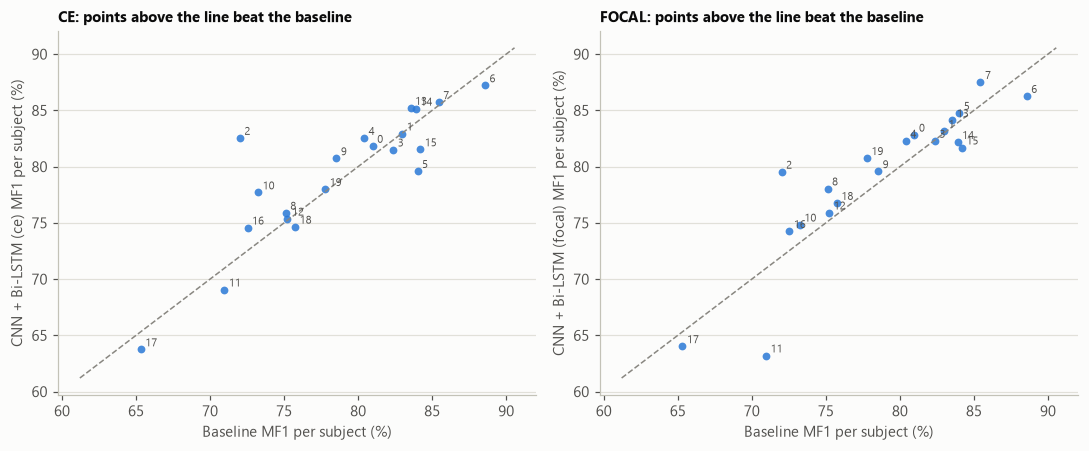

,mean difference (points),subjects where first is better,subjects,Wilcoxon p
ce vs baseline,0.638,12.0,20.0,0.475
focal vs baseline,0.563,14.0,20.0,0.202
focal vs ce,-0.075,11.0,20.0,0.927


In [10]:
def per_subject_mf1(pred, y, subj):
    return pd.Series({s: f1_score(y[(subj == s) & (y >= 0)], pred[(subj == s) & (y >= 0)],
                                  labels=np.unique(y[(subj == s) & (y >= 0)]), average="macro")
                      for s in np.unique(subj[y >= 0])})


subject_all = np.concatenate([[r["subject"]] * len(r["labels"]) for r in records])
rec_all = np.concatenate([[r["rec"]] * len(r["labels"]) for r in records])

# Baseline predictions re-ordered to the same epoch order as `records`
base_key = {(rec, int(e)): k for k, (rec, e) in enumerate(zip(base["rec"], base["epoch_idx"]))}
epoch_idx_all = np.concatenate([np.load(CACHE / f"{r['rec']}.npz")["epoch_idx"] for r in records])
base_pred = base["pred_sc20"][[base_key[(rec, int(e))] for rec, e in zip(rec_all, epoch_idx_all)]]
assert np.array_equal(base["y"][[base_key[(rec, int(e))] for rec, e in zip(rec_all, epoch_idx_all)]], labels_all)

mask = tested
subj_base = per_subject_mf1(base_pred[mask], labels_all[mask], subject_all[mask])
subj = {name: pd.concat([per_subject_mf1(runs[(name, s)]["probs"][mask].argmax(1), labels_all[mask], subject_all[mask])
                         for s in SEEDS], axis=1).mean(axis=1) for name in LOSSES}
per_subject = pd.DataFrame({"baseline": subj_base, **{f"{n}": subj[n] for n in LOSSES}})

tests = {}
for a, b in [("ce", "baseline"), ("focal", "baseline"), ("focal", "ce")]:
    d = per_subject[a] - per_subject[b]                          # paired: same subject, two models
    tests[f"{a} vs {b}"] = {"mean difference (points)": 100 * d.mean(), "subjects where first is better": int((d > 0).sum()),
                            "subjects": len(d), "Wilcoxon p": wilcoxon(per_subject[a], per_subject[b]).pvalue}

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, name in zip(axes, LOSSES):
    ax.scatter(100 * per_subject["baseline"], 100 * per_subject[name], s=26, color=STAGE_COLORS["Wake"], alpha=0.85, linewidths=0)
    lo, hi = 100 * per_subject.min().min() - 2, 100 * per_subject.max().max() + 2
    ax.plot([lo, hi], [lo, hi], color=MUTED, lw=1, ls="--")
    for s, row in per_subject.iterrows():
        ax.annotate(str(s), (100 * row["baseline"], 100 * row[name]), fontsize=7, color=INK_2, xytext=(3, 2), textcoords="offset points")
    ax.set_xlabel("Baseline MF1 per subject (%)")
    ax.set_ylabel(f"CNN + Bi-LSTM ({name}) MF1 per subject (%)")
    ax.set_title(f"{name.upper()}: points above the line beat the baseline", fontsize=10)
fig.tight_layout()
fig.savefig(FIG_DIR / "04_cnn_sc20_per_subject.png")
plt.show()
pd.DataFrame(tests).T.round(3)

**Input.** MF1 tiap subjek dihitung untuk *baseline* dan untuk tiap *loss* (rerata tiga *seed*), lalu dibandingkan per subjek (berpasangan: subjek yang sama, dua model) dengan uji peringkat bertanda Wilcoxon. Satu titik pada grafik adalah satu subjek; titik di atas garis putus-putus berarti model *deep learning* mengalahkan *baseline* pada subjek itu.

**Output.**

| Pasangan | Selisih rerata (poin) | Subjek yang lebih baik | p Wilcoxon |
|---|---|---|---|
| CE vs *baseline* | +0,64 | 12 dari 20 | 0,475 |
| *Focal* vs *baseline* | +0,56 | 14 dari 20 | 0,202 |
| *Focal* vs CE | −0,07 | 11 dari 20 | 0,927 |

**Kesimpulan.** Tidak satu pun perbandingan signifikan (semua p di atas 0,05; dengan hanya 20 subjek, uji ini juga bertenaga rendah). Jadi **belum ada bukti bahwa deep learning lebih baik daripada *baseline* pada SC-20**, dan tidak ada bukti bahwa *focal* berbeda dari CE. Keunggulan terlihat pada subjek tertentu, misalnya subjek 2 (MF1 baseline 72,0 menjadi 82,6 pada CE), sedangkan subjek 11 turun pada *focal* (71,0 menjadi 63,2) dan subjek 5 turun pada CE (84,0 menjadi 79,6). Subjek 11 dan 17 sulit bagi semua model.

### H2. Ke mana setiap tahap salah dibawa

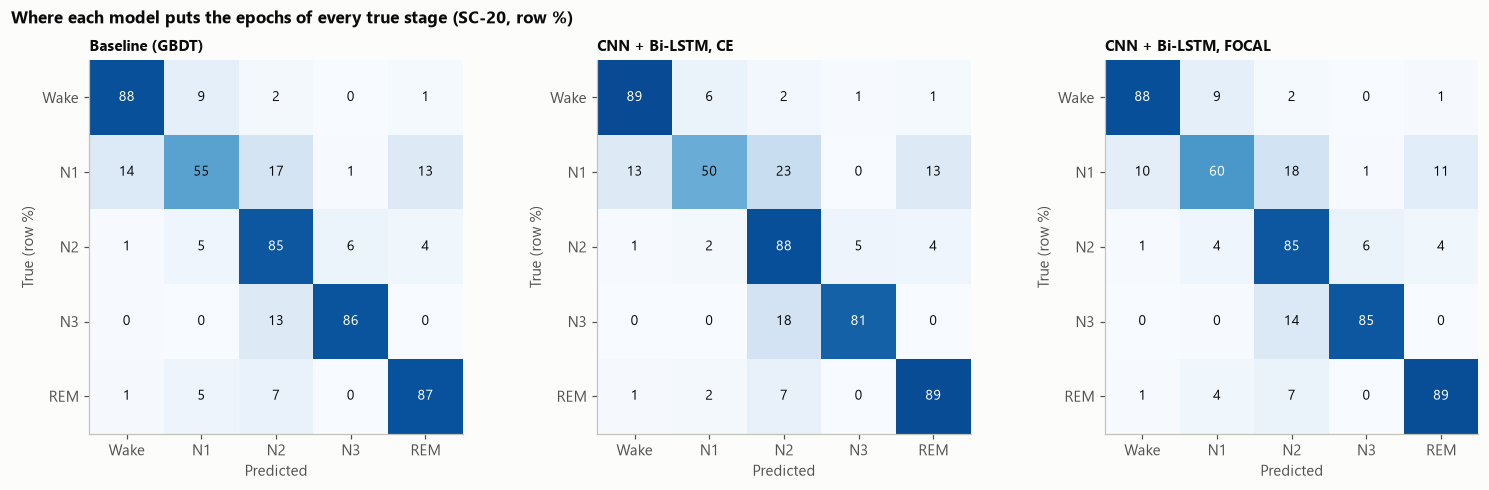

,Wake,N1,N2,N3,REM
Baseline (GBDT),87.5,55.3,85.0,86.1,87.3
"CNN + Bi-LSTM, CE",89.4,50.5,88.1,81.2,89.0
"CNN + Bi-LSTM, FOCAL",87.9,60.1,84.9,85.0,88.6


In [11]:
def row_normalised(y, p):
    cm = confusion_matrix(y, p, labels=range(5)).astype(float)
    return 100 * cm / cm.sum(axis=1, keepdims=True)


matrices = {"Baseline (GBDT)": row_normalised(y_true, base_pred[tested])}
for name in LOSSES:
    matrices[f"CNN + Bi-LSTM, {name.upper()}"] = np.mean([row_normalised(y_true, runs[(name, s)]["probs"][tested].argmax(1))
                                                          for s in SEEDS], axis=0)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
for ax, (title, cm) in zip(axes, matrices.items()):
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=100)
    for r in range(5):
        for c in range(5):
            ax.text(c, r, f"{cm[r, c]:.0f}", ha="center", va="center", fontsize=9, color="white" if cm[r, c] > 60 else INK)
    ax.set_xticks(range(5), STAGES)
    ax.set_yticks(range(5), STAGES)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True (row %)")
    ax.grid(False)
    ax.set_title(title, fontsize=10)
fig.suptitle("Where each model puts the epochs of every true stage (SC-20, row %)", x=0.02, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "04_cnn_sc20_confusion.png")
plt.show()
pd.DataFrame({title: np.diag(cm).round(1) for title, cm in matrices.items()}, index=STAGES).T

**Input.** Matriks kebingungan dinormalkan per baris (persen dari *epoch* sebenarnya tiap tahap), dirata-ratakan pada tiga *seed*, untuk *baseline*, CE, dan *focal*. Tabel di bawah gambar adalah diagonalnya (sensitivitas per tahap).

**Output.** Sensitivitas per tahap (%):

| | Wake | N1 | N2 | N3 | REM |
|---|---|---|---|---|---|
| *Baseline* | 87,5 | 55,3 | 85,0 | 86,1 | 87,3 |
| CNN + Bi-LSTM, CE | 89,4 | 50,5 | 88,1 | 81,2 | 89,0 |
| CNN + Bi-LSTM, *focal* | 87,9 | 60,1 | 84,9 | 85,0 | 88,6 |

**Kesimpulan.** Dua profil berbeda. CE lebih tepat pada Wake, N2, dan REM tetapi **lebih lemah pada N1 dan N3**: 23% *epoch* N1 dibawa ke N2 dan 18% *epoch* N3 dibawa ke N2. *Focal* mengembalikan N1 (60,1%) dan N3 (85,0%) tetapi Wake dan N2 kembali ke tingkat *baseline* (87,9 dan 84,9). Dengan kata lain *focal* memindahkan kapasitas dari kelas besar ke kelas langka (tukar-tambah) dan MF1 hampir tidak berubah. **Penurunan Wake dan N2 yang terlihat pada versi pertama tidak terulang di sini**: tidak ada model yang memiliki sensitivitas Wake atau N2 di bawah *baseline*.

### H3. Letak kesalahan Wake

In [12]:
# Where are the Wake mistakes? Before the first sleep epoch, after the last one, or during the night
position = np.empty(len(labels_all), dtype=object)
for r, a, b in zip(records, np.cumsum([0] + [len(r["labels"]) for r in records])[:-1], np.cumsum([len(r["labels"]) for r in records])):
    sleep = np.flatnonzero((r["labels"] >= 1) & (r["labels"] <= 4))
    idx = np.arange(b - a)
    position[a:b] = np.where(idx < sleep[0], "before sleep", np.where(idx > sleep[-1], "after sleep", "during the night"))

wake = tested & (labels_all == 0)
wake_errors = {}
for title, pred in [("Baseline (GBDT)", base_pred)] + [(f"CNN {n.upper()}", None) for n in LOSSES]:
    for pos in ["before sleep", "during the night", "after sleep"]:
        m = wake & (position == pos)
        if pred is None:
            name = title.split()[-1].lower()
            err = np.mean([np.mean(runs[(name, s)]["probs"][m].argmax(1) != 0) for s in SEEDS])
        else:
            err = np.mean(pred[m] != 0)
        wake_errors.setdefault(title, {})[f"{pos} ({m.sum():,} Wake epochs)"] = 100 * err
pd.DataFrame(wake_errors).T.round(1)

,"before sleep (2,340 Wake epochs)","during the night (3,605 Wake epochs)","after sleep (2,339 Wake epochs)"
Baseline (GBDT),4.8,23.7,2.9
CNN CE,3.9,18.6,4.9
CNN FOCAL,4.6,22.5,3.5


**Input.** Setiap *epoch* Wake diberi posisi: sebelum *epoch* tidur pertama, sesudah *epoch* tidur terakhir, atau di tengah malam. Dihitung persentase Wake yang salah tebak pada tiap posisi.

**Output.** Galat Wake (%):

| | Sebelum tidur (2.340) | Tengah malam (3.605) | Setelah tidur (2.339) |
|---|---|---|---|
| *Baseline* | 4,8 | 23,7 | 2,9 |
| CNN CE | 3,9 | 18,6 | 4,9 |
| CNN *focal* | 4,6 | 22,5 | 3,5 |

**Kesimpulan.** Sebagian besar kesalahan Wake (sekitar 83% pada *baseline*) terjadi **di tengah malam** (terbangun singkat di antara tidur), bukan di ujung malam. CE mengurangi galat tengah malam (23,7 menjadi 18,6) tetapi menambah galat setelah tidur (2,9 menjadi 4,9). Pola ini sejalan dengan dugaan bahwa konteks dua arah membantu mengenali terbangun singkat sekaligus memperhalus transisi akhir malam, namun **dugaan ini belum diuji secara terpisah**; angka di atas hanya menunjukkan letak kesalahan, bukan penyebabnya.

### H4. Kurva pelatihan dan titik henti

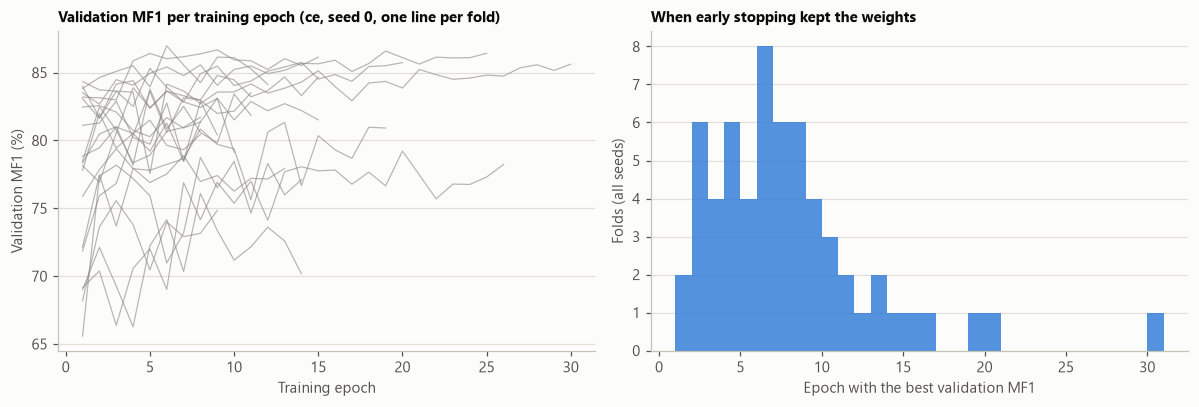

best epoch: median 6, range 1-30 of max 30; training time per run: ce seed 0 31 min, ce seed 1 28 min, ce seed 2 23 min, focal seed 0 30 min, focal seed 1 30 min, focal seed 2 27 min


In [13]:
sel_runs = [runs[(SELECTED, s)] for s in SEEDS]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for fold, hist in sel_runs[0]["history"].items():
    h = pd.DataFrame(hist)
    axes[0].plot(h["epoch"], 100 * h["val_mf1"], color=MUTED, lw=0.8, alpha=0.6)
axes[0].set_xlabel("Training epoch")
axes[0].set_ylabel("Validation MF1 (%)")
axes[0].set_title(f"Validation MF1 per training epoch ({SELECTED}, seed {SEEDS[0]}, one line per fold)", fontsize=10)
stops = np.concatenate([r["best_epoch"] for r in sel_runs])
axes[1].hist(stops, bins=range(1, CONFIG["max_epochs"] + 2), color=STAGE_COLORS["Wake"], alpha=0.8)
axes[1].set_xlabel("Epoch with the best validation MF1")
axes[1].set_ylabel("Folds (all seeds)")
axes[1].set_title("When early stopping kept the weights", fontsize=10)
fig.tight_layout()
fig.savefig(FIG_DIR / "04_cnn_sc20_training.png")
plt.show()
print(f"best epoch: median {np.median(stops):.0f}, range {stops.min()}-{stops.max()} of max {CONFIG['max_epochs']}; "
      f"training time per run: " + ", ".join(f"{k[0]} seed {k[1]} {v['minutes']:.0f} min" for k, v in runs.items()))

**Input.** Macro-F1 validasi tiap putaran latih untuk 20 *fold* (CE, *seed* 0), dan histogram putaran yang bobotnya dipertahankan pada semua *seed* dan *fold* untuk *loss* terpilih.

**Output.** Putaran terbaik: median 6, rentang 1 sampai 30 dari maksimal 30. Kurva validasi naik cepat lalu mendatar atau berfluktuasi sekitar 1 sampai 3 poin.

**Kesimpulan.** Model mencapai kinerja terbaik pada validasi dalam beberapa putaran saja, lalu mulai menghafal subjek latih; kurva yang berfluktuasi menunjukkan bahwa 2 subjek validasi masih berisik walau lebih baik daripada 1 subjek. Batas 30 putaran tidak membatasi hasil (hanya satu *fold* menyentuhnya). Artinya keterbatasan utama bukan lamanya pelatihan melainkan sedikitnya subjek latih (17).

### H5. Hipnogram satu rekaman

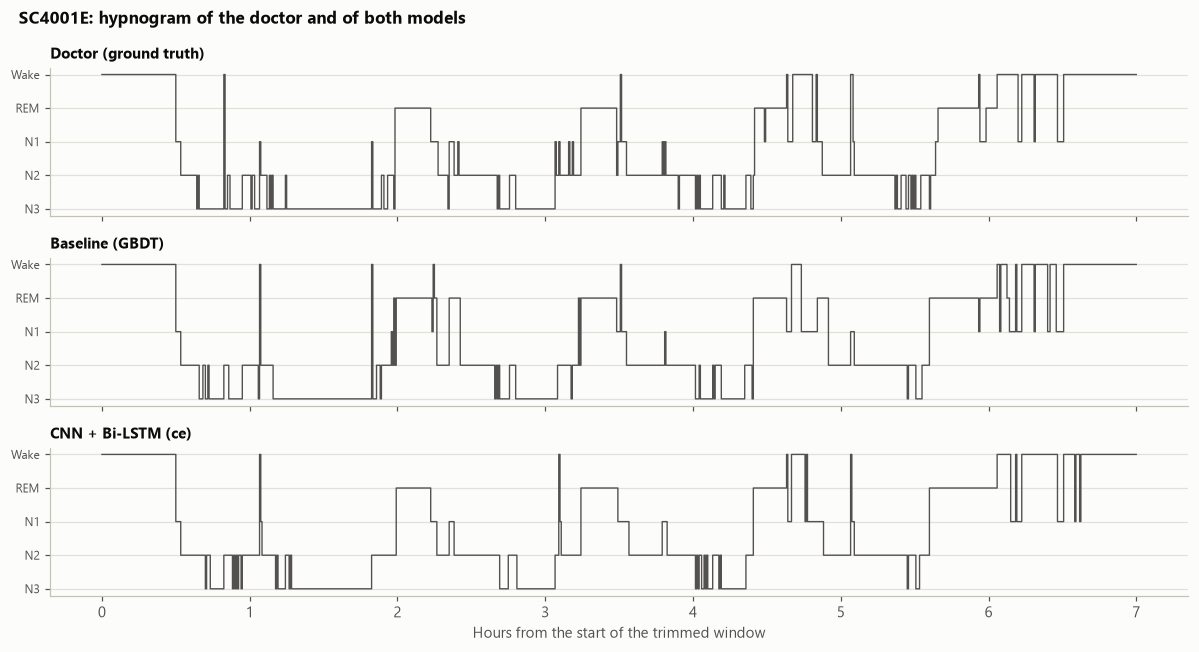

SC4001E agreement with the doctor: {'Baseline (GBDT)': '86.2%', 'CNN + Bi-LSTM (ce)': '86.7%'}


In [14]:
LEVEL = {0: 4, 4: 3, 1: 2, 2: 1, 3: 0}
REC_SHOW = "SC4001E"
m = rec_all == REC_SHOW
cnn_probs = np.mean([run["probs"][m] for run in sel_runs], axis=0)
show = {"Doctor (ground truth)": labels_all[m], "Baseline (GBDT)": base_pred[m], f"CNN + Bi-LSTM ({SELECTED})": cnn_probs.argmax(1)}

fig, axes = plt.subplots(3, 1, figsize=(11, 6), sharex=True)
hours = np.arange(m.sum()) * 30 / 3600
for ax, (title, lab) in zip(axes, show.items()):
    level = np.array([LEVEL.get(int(l), np.nan) for l in lab], dtype=float)
    ax.step(hours, level, where="post", color=INK_2, lw=0.9)
    ax.set_yticks([4, 3, 2, 1, 0], ["Wake", "REM", "N1", "N2", "N3"], fontsize=8)
    ax.set_title(title, fontsize=10)
axes[-1].set_xlabel("Hours from the start of the trimmed window")
fig.suptitle(f"{REC_SHOW}: hypnogram of the doctor and of both models", x=0.02, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "04_cnn_sc20_hypnogram.png")
plt.show()
agree = {k: f"{100 * np.mean(v[labels_all[m] >= 0] == labels_all[m][labels_all[m] >= 0]):.1f}%" for k, v in list(show.items())[1:]}
print(f"{REC_SHOW} agreement with the doctor:", agree)

**Input.** Hipnogram rekaman SC4001E (841 *epoch*, sekitar 7 jam) menurut dokter, *baseline*, dan CNN + Bi-LSTM (*loss* terpilih, rerata tiga *seed*), serta kesepakatan tiap model dengan dokter.

**Output.** Kesepakatan dengan dokter: *baseline* 86,2% dan CNN + Bi-LSTM 86,7%.

**Kesimpulan.** Kedua model mengikuti struktur malam (siklus N3, REM, dan terbangun pagi). Prediksi CNN tampak sedikit lebih halus daripada *baseline*. Selisih 0,5 poin pada **satu rekaman** hanya ilustrasi dan bukan bukti; bukti ada pada Bagian G dan H1.

## Bagian I. Penyimpanan hasil

Menulis tabel dan prediksi agar dapat dipakai dokumen dan fase berikutnya.

In [15]:
per_run.to_csv(TAB_DIR / "04_cnn_sc20_runs.csv", index=False)
table.to_csv(TAB_DIR / "04_cnn_sc20_metrics.csv")
per_subject.to_csv(TAB_DIR / "04_cnn_sc20_per_subject.csv")
pd.DataFrame(tests).T.to_csv(TAB_DIR / "04_cnn_sc20_paired_tests.csv")
pd.DataFrame(wake_errors).T.to_csv(TAB_DIR / "04_cnn_sc20_wake_errors.csv")
np.savez(PREDICTIONS, rec=rec_all, epoch_idx=epoch_idx_all, y=labels_all,
         **{f"probs_{n}": np.mean([runs[(n, s)]["probs"] for s in SEEDS], axis=0) for n in LOSSES})
print("tables:", sorted(p.name for p in TAB_DIR.glob("04_cnn_sc20_*.csv")))
print(f"selected: {SELECTED}; test MF1 {100 * summary.loc[SELECTED, ('MF1', 'mean')]:.1f} ± "
      f"{100 * summary.loc[SELECTED, ('MF1', 'std')]:.1f} vs baseline {100 * float(baseline_sc20['MF1']):.1f}")

tables: ['04_cnn_sc20_metrics.csv', '04_cnn_sc20_paired_tests.csv', '04_cnn_sc20_per_subject.csv', '04_cnn_sc20_runs.csv', '04_cnn_sc20_wake_errors.csv']
selected: ce; test MF1 80.1 ± 0.4 vs baseline 79.2


**Input.** Tabel per-*run*, ringkasan, MF1 per subjek, hasil uji berpasangan, dan galat Wake ditulis ke `results/tables/04_cnn_sc20_*.csv`; peluang model terpilih (rerata *seed*) disimpan ke `data/processed/cnn_sc20_predictions.npz` (diabaikan git).

**Output.** Lima tabel tertulis. "selected: ce; test MF1 80.1 ± 0.4 vs baseline 79.2".

**Kesimpulan.** Model terpilih pada SC-20: CE dengan MF1 80,1 ± 0,4 (*baseline* 79,2). Perbaikan sekitar satu poin bersifat **belum terbukti signifikan**. Langkah berikutnya (SC-78 dan SC-20 + ST) hanya bermakna bila arsitektur ini dipertahankan; keputusan tersebut dicatat pada K6.